# Assignment 6: Tree-Based Methods
**Amari Ware** · DDS-8555 Predictive Analysis · National University

**Contents**
1. ISLP Chapter 8, Conceptual Question 1: a recursive binary partition and its decision tree
2. ISLP Chapter 8, Applied Question 12: bagging, random forests, boosting and BART vs. linear and regularized regression (`Carseats`)
3. Kaggle, Multi-class Prediction of Obesity Risk (Playground Series S4E2): decision tree, bagging, random forest and boosting, with a regularized logistic regression baseline

In [1]:
import sys, subprocess, importlib
try:
    importlib.import_module('ISLP')
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ISLP'], check=True)

import os, warnings, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import seaborn as sns
import sklearn
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
FIG_DIR = os.path.join(OUT_DIR, 'figures'); os.makedirs(FIG_DIR, exist_ok=True)
print('scikit-learn', sklearn.__version__, '| output folder:', OUT_DIR)

scikit-learn 1.6.1 | output folder: /kaggle/working


## Part 1. Conceptual Question 1

> Draw an example (of your own invention) of a partition of two-dimensional feature space that could result from recursive binary splitting. The example should contain at least six regions. Draw a decision tree corresponding to this partition, labeling the regions $R_1, R_2, \ldots$ and the cutpoints $t_1, t_2, \ldots$.

The partition below uses six cutpoints and produces **seven regions**. Each split divides one existing region in two along a single predictor, which is exactly how recursive binary splitting works: the first split ($X_1 < t_1$) cuts the whole space, and every later split applies only inside the region it refines.

| Split | Rule | Applies within |
|---|---|---|
| $t_1 = 4$ | $X_1 < 4$ | whole space |
| $t_2 = 6$ | $X_2 < 6$ | $X_1 < 4$ |
| $t_3 = 2$ | $X_1 < 2$ | $X_1 < 4,\ X_2 \ge 6$ |
| $t_4 = 3$ | $X_2 < 3$ | $X_1 \ge 4$ |
| $t_5 = 7$ | $X_1 < 7$ | $X_1 \ge 4,\ X_2 \ge 3$ |
| $t_6 = 8$ | $X_2 < 8$ | $X_1 \ge 7,\ X_2 \ge 3$ |

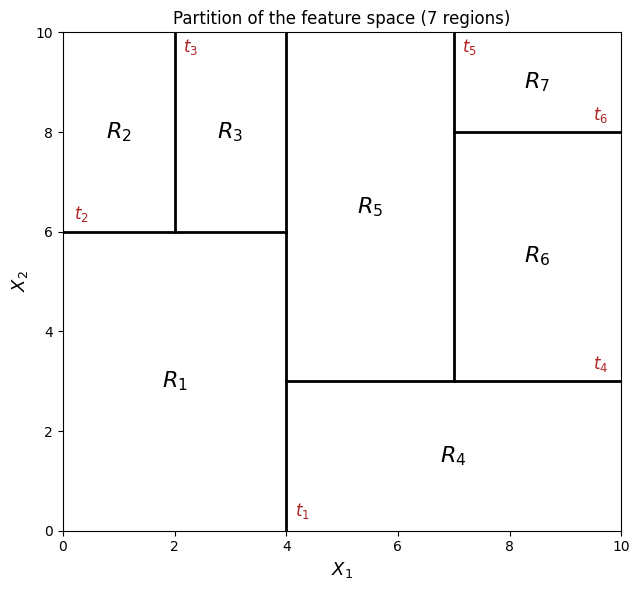

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.set_xlim(0, 10); ax.set_ylim(0, 10)
lw = 2
ax.axvline(4, color='k', lw=lw)                       # t1: X1 = 4
ax.plot([0, 4], [6, 6], 'k', lw=lw)                   # t2: X2 = 6 (left side)
ax.plot([2, 2], [6, 10], 'k', lw=lw)                  # t3: X1 = 2 (upper left)
ax.plot([4, 10], [3, 3], 'k', lw=lw)                  # t4: X2 = 3 (right side)
ax.plot([7, 7], [3, 10], 'k', lw=lw)                  # t5: X1 = 7 (upper right)
ax.plot([7, 10], [8, 8], 'k', lw=lw)                  # t6: X2 = 8 (far right)
labels = {'R1': (2, 3), 'R2': (1, 8), 'R3': (3, 8), 'R4': (7, 1.5),
          'R5': (5.5, 6.5), 'R6': (8.5, 5.5), 'R7': (8.5, 9)}
for k, (x, y) in labels.items():
    ax.text(x, y, f'$R_{k[1]}$', ha='center', va='center', fontsize=16)
for txt, (x, y) in {'$t_1$': (4.15, 0.3), '$t_2$': (0.2, 6.25), '$t_3$': (2.15, 9.6),
                    '$t_4$': (9.5, 3.25), '$t_5$': (7.15, 9.6), '$t_6$': (9.5, 8.25)}.items():
    ax.text(x, y, txt, fontsize=12, color='firebrick')
ax.set_xlabel('$X_1$', fontsize=13); ax.set_ylabel('$X_2$', fontsize=13)
ax.set_title('Partition of the feature space (7 regions)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/q1_partition.png', dpi=150); plt.show()

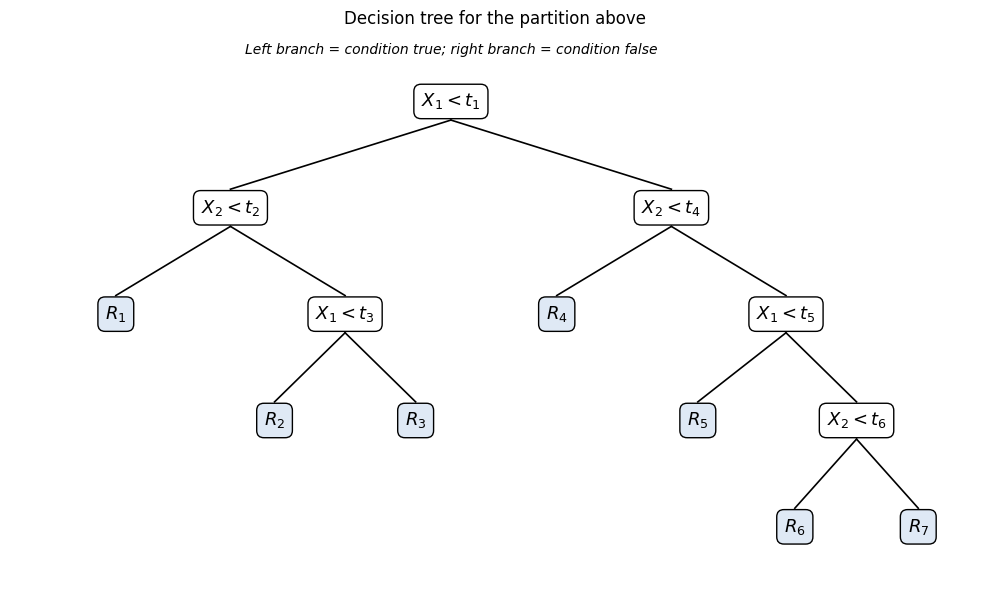

In [3]:
def draw_tree():
    fig, ax = plt.subplots(figsize=(10, 6)); ax.axis('off')
    nodes = {  # name: (x, y, label)
        'n1': (5, 9, '$X_1 < t_1$'),
        'n2': (2.5, 7, '$X_2 < t_2$'), 'n3': (7.5, 7, '$X_2 < t_4$'),
        'R1': (1.2, 5, '$R_1$'), 'n4': (3.8, 5, '$X_1 < t_3$'),
        'R4': (6.2, 5, '$R_4$'), 'n5': (8.8, 5, '$X_1 < t_5$'),
        'R2': (3.0, 3, '$R_2$'), 'R3': (4.6, 3, '$R_3$'),
        'R5': (7.8, 3, '$R_5$'), 'n6': (9.6, 3, '$X_2 < t_6$'),
        'R6': (8.9, 1, '$R_6$'), 'R7': (10.3, 1, '$R_7$')}
    edges = [('n1','n2'),('n1','n3'),('n2','R1'),('n2','n4'),('n3','R4'),('n3','n5'),
             ('n4','R2'),('n4','R3'),('n5','R5'),('n5','n6'),('n6','R6'),('n6','R7')]
    for a, b in edges:
        (x1, y1, _), (x2, y2, _) = nodes[a], nodes[b]
        ax.plot([x1, x2], [y1 - 0.35, y2 + 0.35], 'k-', lw=1.2)
    for name, (x, y, lab) in nodes.items():
        leaf = name.startswith('R')
        ax.text(x, y, lab, ha='center', va='center', fontsize=13,
                bbox=dict(boxstyle='round,pad=0.4', fc='#dfe9f5' if leaf else 'white', ec='k'))
    ax.text(5, 9.9, 'Left branch = condition true; right branch = condition false', ha='center', fontsize=10, style='italic')
    ax.set_xlim(0, 11); ax.set_ylim(0, 10.3)
    ax.set_title('Decision tree for the partition above')
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/q1_tree.png', dpi=150); plt.show()
draw_tree()

**Reading the tree.** Each internal node tests one predictor against one cutpoint; the left branch is followed when the condition is true. Every path from the root to a leaf traces the boundaries of one rectangle in the partition. For example, $R_6$ is reached by $X_1 \ge t_1$, $X_2 \ge t_4$, $X_1 \ge t_5$ and $X_2 < t_6$, which is the box $7 \le X_1 \le 10,\ 3 \le X_2 < 8$. Because each split only refines an existing region, the regions never overlap and together they cover the whole space. A regression tree would predict the mean response of the training observations in each region; a classification tree would predict the most common class.

## Part 2. Applied Question 12

> Apply boosting, bagging, random forests, and BART to a data set of your choice. Fit the models on a training set and evaluate their performance on a test set. How accurate are the results compared to simple methods like linear or logistic regression? Which of these approaches yields the best performance?

**Data.** `Carseats` from the ISLP package: unit sales (in thousands) of child car seats at 400 stores, with price, competitor price, advertising, shelf location and demographics as predictors. The response `Sales` is continuous, so the simple comparisons are **least-squares linear regression** and its regularized versions, **ridge and lasso**, with penalties chosen by 10-fold cross-validation. The data are split 50/50 into training and test sets, and all models are compared on **test mean squared error (MSE)**.

In [4]:
from ISLP import load_data
from ISLP.bart import BART
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

car = load_data('Carseats')
Xc = pd.get_dummies(car.drop(columns='Sales'), drop_first=True).astype(float)
yc = car['Sales']
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.5, random_state=0)
print('Train', Xtr.shape, '| Test', Xte.shape, '| predictors:', list(Xc.columns))
p = Xc.shape[1]
alphas = np.logspace(-3, 3, 100)

reg_models = {
    'Linear regression (OLS)': LinearRegression(),
    'Ridge regression (CV)':   make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=10)),
    'Lasso (CV)':              make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=10, random_state=0, max_iter=50000)),
    'Bagging (m = p)':         RandomForestRegressor(n_estimators=500, max_features=p, random_state=0, n_jobs=-1),
    'Random forest (m = p/3)': RandomForestRegressor(n_estimators=500, max_features=max(1, p // 3), random_state=0, n_jobs=-1),
    'Boosting':                GradientBoostingRegressor(n_estimators=1000, learning_rate=0.01, max_depth=3, random_state=0),
    'BART':                    BART(random_state=0, burnin=5, ndraw=15),
}
rows = []
for name, m in reg_models.items():
    m.fit(Xtr.values if name == 'BART' else Xtr, ytr.values if name == 'BART' else ytr)
    pred = m.predict(Xte.values if name == 'BART' else Xte)
    rows.append((name, mean_squared_error(yte, pred)))
q12 = pd.DataFrame(rows, columns=['Model', 'Test MSE']).sort_values('Test MSE').reset_index(drop=True)
q12['Test RMSE'] = np.sqrt(q12['Test MSE'])
display(q12.round(3))

Train (200, 11) | Test (200, 11) | predictors: ['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education', 'ShelveLoc_Good', 'ShelveLoc_Medium', 'Urban_Yes', 'US_Yes']


,Model,Test MSE,Test RMSE
0,Lasso (CV),1.107,1.052
1,Ridge regression (CV),1.112,1.055
2,Linear regression (OLS),1.125,1.061
3,BART,1.561,1.249
4,Boosting,1.942,1.394
5,Bagging (m = p),2.677,1.636
6,Random forest (m = p/3),2.983,1.727


Ridge penalty chosen by CV: 0.9326 | Lasso penalty chosen by CV: 0.0071
Lasso set to zero: none


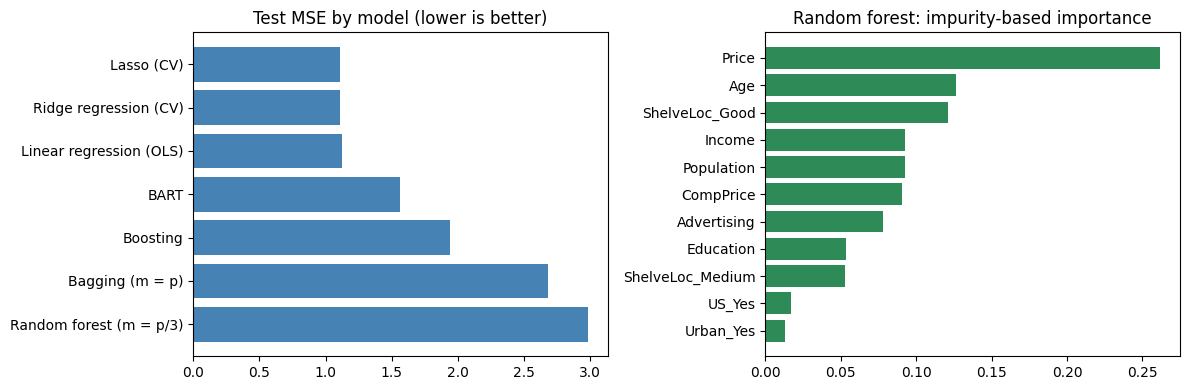

Best model: Lasso (CV) (test MSE 1.107); OLS test MSE 1.125.


In [5]:
lasso = reg_models['Lasso (CV)'][-1]
ridge = reg_models['Ridge regression (CV)'][-1]
print(f'Ridge penalty chosen by CV: {ridge.alpha_:.4f} | Lasso penalty chosen by CV: {lasso.alpha_:.4f}')
coef = pd.Series(lasso.coef_, index=Xc.columns)
print('Lasso set to zero:', list(coef[coef == 0].index) or 'none')

rf = reg_models['Random forest (m = p/3)']
imp = pd.Series(rf.feature_importances_, index=Xc.columns).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(q12['Model'][::-1], q12['Test MSE'][::-1], color='steelblue'); axes[0].set_title('Test MSE by model (lower is better)')
axes[1].barh(imp.index, imp.values, color='seagreen'); axes[1].set_title('Random forest: impurity-based importance')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/q12_results.png', dpi=150); plt.show()

best = q12.iloc[0]; ols = q12.set_index('Model').loc['Linear regression (OLS)', 'Test MSE']
print(f"Best model: {best['Model']} (test MSE {best['Test MSE']:.3f}); OLS test MSE {ols:.3f}.")

**Interpretation.** The table ranks every model on the same held-out stores. Two points stand out in the results above:

* **Linear models are hard to beat here.** `Carseats` sales respond close to linearly to price, shelf location, competitor price and advertising, so ordinary least squares already captures most of the signal. Ridge and lasso land very close to OLS: with only 11 predictors and 200 training stores, there is little variance for the penalty to remove. The lasso output shows which weak predictors (if any) it dropped.
* **Among the tree ensembles, BART and boosting beat bagging and random forests.** Bagging and random forests average deep trees, which approximate a linear surface with many small steps and lose accuracy on additive linear effects. BART and boosting build the fit from many small trees added together, which mimics an additive model and recovers the linear structure much more closely. Here the random forest does slightly worse than bagging: with only 11 predictors and two dominant ones (`Price` and shelf location), allowing just $p/3$ predictors per split often hides the strongest predictor from a split, so decorrelating the trees costs more than it saves.

So the answer to "which approach is best" depends on the structure of the data: when the true relationship is close to linear and additive, a linear model (or an additive ensemble like boosting or BART) wins; tree ensembles pay off when interactions and nonlinearities dominate, as in Part 3. The importance plot confirms that `Price` and `ShelveLoc_Good` drive sales.

## Part 3. Kaggle: Multi-class Prediction of Obesity Risk (Playground Series S4E2)

**Goal:** predict `NObeyesdad` (seven weight classes) from demographics, eating habits and activity. **Metric:** accuracy.

This section runs inside a Kaggle notebook attached to the competition data. Four tree-based models are required: a **single decision tree**, **bagging**, a **random forest** and **gradient boosting**. A **regularized (L2) multinomial logistic regression** is included as a linear baseline. Each model is scored with **5-fold stratified cross-validation**, refit on all training rows, and written to its own submission file.

In [6]:
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

DATA_DIR = next((d for d in ['/kaggle/input/playground-series-s4e2', '/kaggle/input/competitions/playground-series-s4e2', '.']
                 if os.path.exists(os.path.join(d, 'train.csv'))), '.')
train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
print('Data from:', DATA_DIR, '| train', train.shape, '| test', test.shape)
train.head()

Data from: /kaggle/input/competitions/playground-series-s4e2 | train (20758, 18) | test (13840, 17)


,id,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,0,Male,24.443011,1.699998,81.669950,yes,yes,2.000000,2.983297,Sometimes,no,2.763573,no,0.000000,0.976473,Sometimes,Public_Transportation,Overweight_Level_II
1,1,Female,18.000000,1.560000,57.000000,yes,yes,2.000000,3.000000,Frequently,no,2.000000,no,1.000000,1.000000,no,Automobile,Normal_Weight
2,2,Female,18.000000,1.711460,50.165754,yes,yes,1.880534,1.411685,Sometimes,no,1.910378,no,0.866045,1.673584,no,Public_Transportation,Insufficient_Weight
3,3,Female,20.952737,1.710730,131.274851,yes,yes,3.000000,3.000000,Sometimes,no,1.674061,no,1.467863,0.780199,Sometimes,Public_Transportation,Obesity_Type_III
4,4,Male,31.641081,1.914186,93.798055,yes,yes,2.679664,1.971472,Sometimes,no,1.979848,no,1.967973,0.931721,Sometimes,Public_Transportation,Overweight_Level_II


### 3.1 Exploratory analysis and feature engineering

Missing values: 0 (train) 0 (test)


,share of training rows
NObeyesdad,
Insufficient_Weight,0.122
Normal_Weight,0.148
Overweight_Level_I,0.117
Overweight_Level_II,0.121
Obesity_Type_I,0.140
Obesity_Type_II,0.156
Obesity_Type_III,0.195


Majority-class baseline accuracy: 0.1949
CALC: levels in test but not in train -> {'Always'} (handled by the encoder)


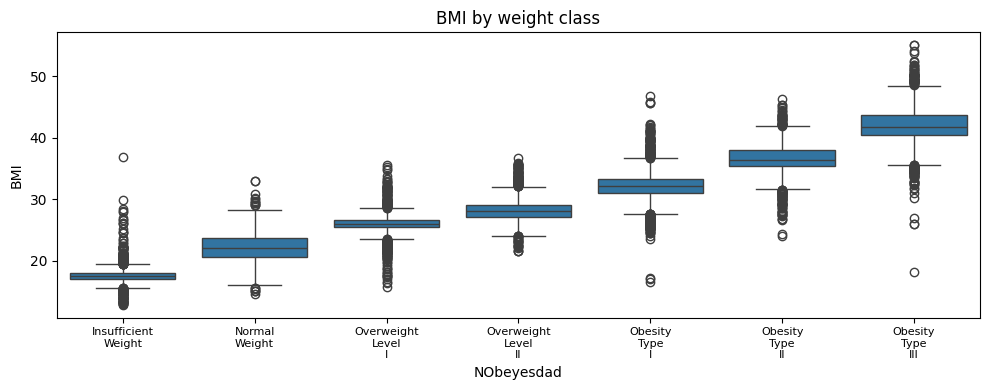

In [7]:
TARGET = 'NObeyesdad'
ORDER = ['Insufficient_Weight','Normal_Weight','Overweight_Level_I','Overweight_Level_II',
         'Obesity_Type_I','Obesity_Type_II','Obesity_Type_III']
cat_cols = ['Gender','family_history_with_overweight','FAVC','CAEC','SMOKE','SCC','CALC','MTRANS']
print('Missing values:', int(train.isna().sum().sum()), '(train)', int(test.isna().sum().sum()), '(test)')
counts = train[TARGET].value_counts().reindex(ORDER)
display((counts / len(train)).round(3).to_frame('share of training rows'))
print('Majority-class baseline accuracy:', round(counts.max() / len(train), 4))
for c in cat_cols:
    unseen = set(test[c].unique()) - set(train[c].unique())
    if unseen: print(f'{c}: levels in test but not in train -> {unseen} (handled by the encoder)')

# Body-mass index (kg/m^2). The original class labels were assigned from BMI cut-points.
for df in (train, test):
    df['BMI'] = df['Weight'] / df['Height'] ** 2
num_cols = ['Age','Height','Weight','BMI','FCVC','NCP','CH2O','FAF','TUE']

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=train, x=TARGET, y='BMI', order=ORDER, ax=ax)
ax.set_xticklabels([o.replace('_', '\n') for o in ORDER], fontsize=8); ax.set_title('BMI by weight class')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/bmi_by_class.png', dpi=150); plt.show()

### 3.2 Assumption checks

Tree-based methods make **no distributional assumptions**: they do not need normality, linearity, equal variances or scaling, and they handle interactions automatically. The assumptions that still matter are:

1. **Training and test rows come from the same distribution** (otherwise CV accuracy will not carry over to the leaderboard). Checked below with Kolmogorov–Smirnov tests on each numeric feature.
2. **Observations are independent.** These are synthetic rows generated from one survey dataset, so independence cannot be tested directly; stratified CV is used and the CV-to-leaderboard agreement serves as the check.
3. **Class balance is reasonable.** Trees split on impurity, so a heavily dominant class can crowd out small ones. The class shares above show whether stratification is needed (it is used regardless).
4. **Correlated predictors.** Correlation does not hurt tree predictions, but it splits importance across related features (Height, Weight and BMI), which matters when interpreting importance scores.
5. **Overfitting.** A single deep tree has low bias and high variance. Comparing training accuracy with CV accuracy shows how much each method overfits.

,feature,KS statistic,p-value
0,Age,0.0130,0.1181
1,Height,0.0180,0.0089
2,Weight,0.0111,0.2536
3,BMI,0.0128,0.1320
4,FCVC,0.0076,0.7237
5,NCP,0.0079,0.6777
6,CH2O,0.0088,0.5443
7,FAF,0.0073,0.7684
8,TUE,0.0135,0.0973


Largest train/test KS distance: 0.018 (values below about 0.02 mean the distributions are practically identical)


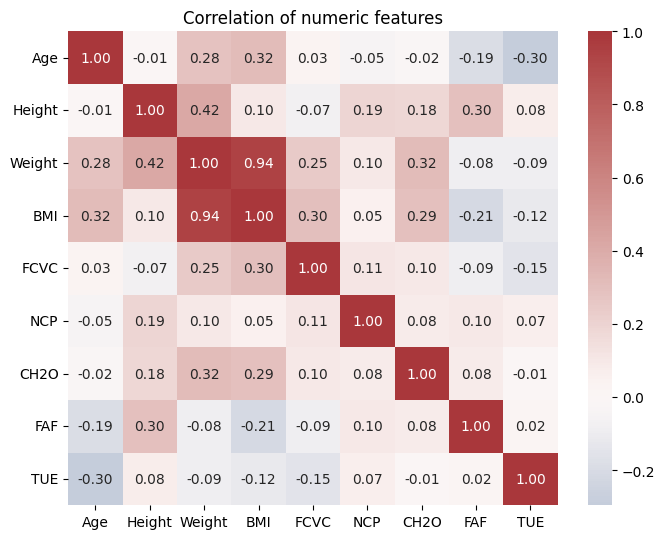

In [8]:
ks = pd.DataFrame([(c, *stats.ks_2samp(train[c], test[c])) for c in num_cols],
                  columns=['feature', 'KS statistic', 'p-value']).round(4)
display(ks)
print('Largest train/test KS distance:', ks['KS statistic'].max(),
      '(values below about 0.02 mean the distributions are practically identical)')
corr = train[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax); ax.set_title('Correlation of numeric features')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/correlation.png', dpi=150); plt.show()

### 3.3 Models

In [9]:
X = train.drop(columns=['id', TARGET]); y = train[TARGET]
X_test = test.drop(columns=['id'])
enc = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)],
                        remainder='passthrough', verbose_feature_names_out=False)
enc.fit(pd.concat([X, X_test]))
Xe, Xe_test = enc.transform(X), enc.transform(X_test)
feat_names = list(enc.get_feature_names_out())
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results, fitted = {}, {}

def record(name, model, cv_acc, note=''):
    model.fit(Xe, y)
    fitted[name] = model
    results[name] = {'CV accuracy': cv_acc, 'Train accuracy': accuracy_score(y, model.predict(Xe)), 'Setting': note}
    print(f'{name}: CV {cv_acc:.4f} | train {results[name]["Train accuracy"]:.4f} | {note}')

# 1. Single decision tree, depth and leaf size tuned by CV
t0 = time.time()
tree_gs = GridSearchCV(DecisionTreeClassifier(random_state=42),
                       {'max_depth': [4, 6, 8, 10, 12, None], 'min_samples_leaf': [1, 5, 20, 50]},
                       cv=cv, scoring='accuracy', n_jobs=-1).fit(Xe, y)
record('Decision tree', tree_gs.best_estimator_, tree_gs.best_score_, str(tree_gs.best_params_))

# 2. Bagging: 300 full-depth trees on bootstrap samples, all predictors at every split
bag = BaggingClassifier(DecisionTreeClassifier(random_state=42), n_estimators=300, oob_score=True,
                        random_state=42, n_jobs=-1)
record('Bagging', bag, cross_val_score(bag, Xe, y, cv=cv, scoring='accuracy', n_jobs=-1).mean(), '300 trees')
print('  Bagging out-of-bag accuracy:', round(fitted['Bagging'].oob_score_, 4))

# 3. Random forest: the number of predictors per split (mtry) chosen by out-of-bag accuracy
oob = {}
for mf in ['sqrt', 0.33, 0.5]:
    m = RandomForestClassifier(n_estimators=500, max_features=mf, oob_score=True, random_state=42, n_jobs=-1).fit(Xe, y)
    oob[mf] = m.oob_score_
best_mf = max(oob, key=oob.get); print('  Random forest OOB accuracy by max_features:', {k: round(v, 4) for k, v in oob.items()})
rf = RandomForestClassifier(n_estimators=500, max_features=best_mf, oob_score=True, random_state=42, n_jobs=-1)
record('Random forest', rf, cross_val_score(rf, Xe, y, cv=cv, scoring='accuracy', n_jobs=-1).mean(), f'max_features={best_mf}')

# 4. Gradient boosting (histogram-based), learning rate and tree size tuned by CV, early stopping on a validation split
gb_gs = GridSearchCV(HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                                    n_iter_no_change=30, random_state=42),
                     {'learning_rate': [0.03, 0.1], 'max_leaf_nodes': [15, 31], 'l2_regularization': [0.0, 1.0]},
                     cv=cv, scoring='accuracy', n_jobs=-1).fit(Xe, y)
record('Boosting', gb_gs.best_estimator_, gb_gs.best_score_, str(gb_gs.best_params_))

# Baseline: L2-regularized multinomial logistic regression, penalty strength chosen by 5-fold CV
logit = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=10, cv=cv, max_iter=3000, n_jobs=-1))
record('Regularized logistic (baseline)', logit,
       cross_val_score(logit, Xe, y, cv=cv, scoring='accuracy', n_jobs=-1).mean(), 'L2 penalty, C chosen by CV')
print(f'All models fitted in {time.time() - t0:.0f} s')

Decision tree: CV 0.8763 | train 0.9003 | {'max_depth': 10, 'min_samples_leaf': 5}
Bagging: CV 0.8912 | train 1.0000 | 300 trees
  Bagging out-of-bag accuracy: 0.8931
  Random forest OOB accuracy by max_features: {'sqrt': 0.9024, 0.33: 0.9015, 0.5: 0.9}
Random forest: CV 0.9017 | train 1.0000 | max_features=sqrt
Boosting: CV 0.9048 | train 0.9622 | {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 31}
Regularized logistic (baseline): CV 0.8669 | train 0.8687 | L2 penalty, C chosen by CV
All models fitted in 244 s


### 3.4 Write the submission files

In [10]:
files = {'Decision tree': 'submission_decision_tree.csv', 'Bagging': 'submission_bagging.csv',
         'Random forest': 'submission_random_forest.csv', 'Boosting': 'submission_boosting.csv',
         'Regularized logistic (baseline)': 'submission_logistic_baseline.csv'}
for name, f in files.items():
    sub = pd.DataFrame({'id': test['id'], TARGET: fitted[name].predict(Xe_test)})
    sub.to_csv(os.path.join(OUT_DIR, f), index=False)
    print(f'{f}: {len(sub)} rows, {sub[TARGET].nunique()} classes predicted')
summary = pd.DataFrame(results).T
summary['Overfit gap (train - CV)'] = summary['Train accuracy'] - summary['CV accuracy']
summary = summary.sort_values('CV accuracy', ascending=False)
display(summary[['CV accuracy', 'Train accuracy', 'Overfit gap (train - CV)', 'Setting']].round(4))

submission_decision_tree.csv: 13840 rows, 7 classes predicted
submission_bagging.csv: 13840 rows, 7 classes predicted
submission_random_forest.csv: 13840 rows, 7 classes predicted
submission_boosting.csv: 13840 rows, 7 classes predicted
submission_logistic_baseline.csv: 13840 rows, 7 classes predicted


,CV accuracy,Train accuracy,Overfit gap (train - CV),Setting
Boosting,0.904808,0.962183,0.057376,"{'l2_regularization': 1.0, 'learning_rate': 0...."
Random forest,0.901676,1.0,0.098324,max_features=sqrt
Bagging,0.891174,1.0,0.108826,300 trees
Decision tree,0.876288,0.900328,0.024039,"{'max_depth': 10, 'min_samples_leaf': 5}"
Regularized logistic (baseline),0.866894,0.868725,0.001831,"L2 penalty, C chosen by CV"


### 3.5 Interpretation

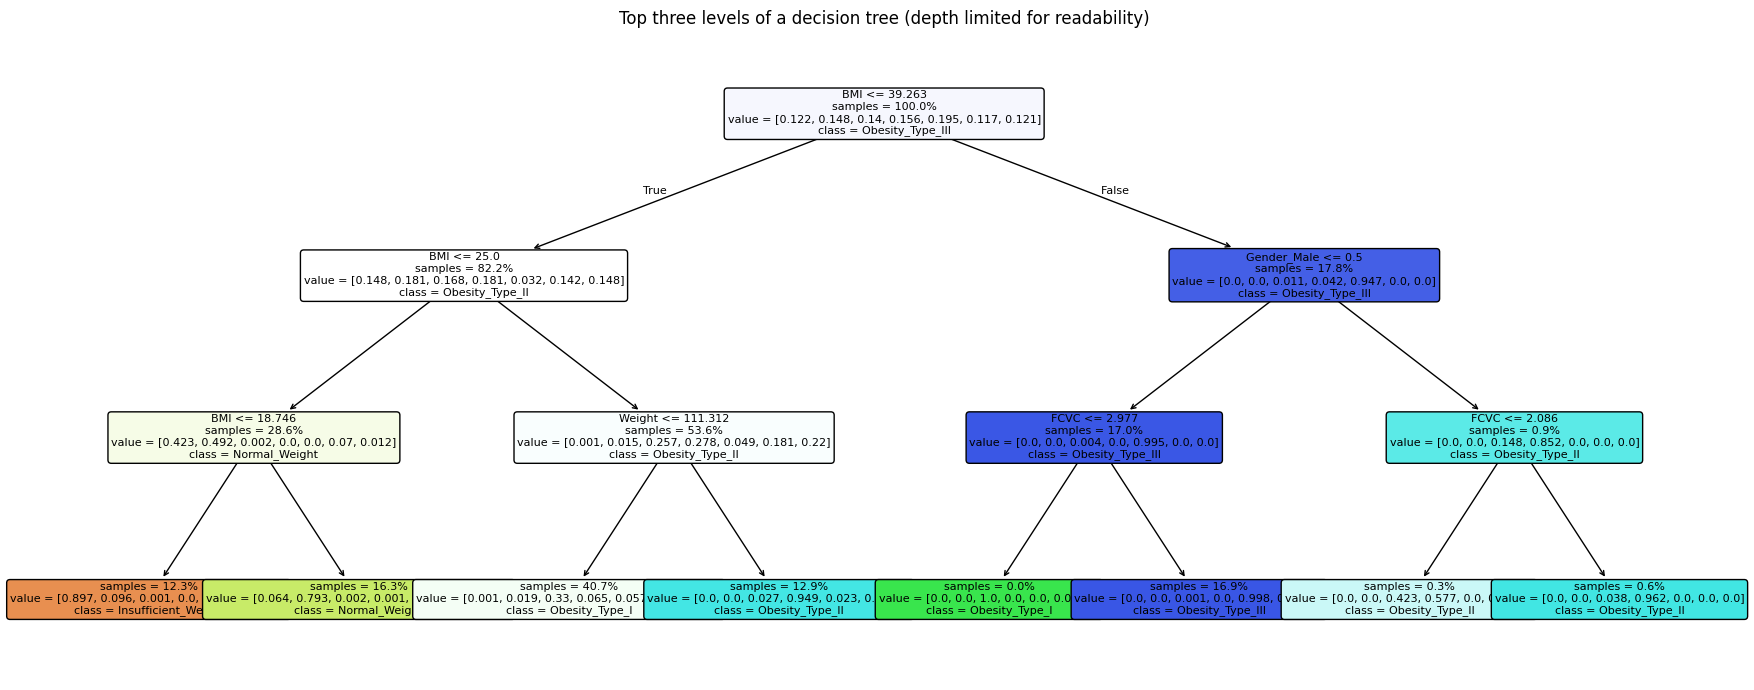

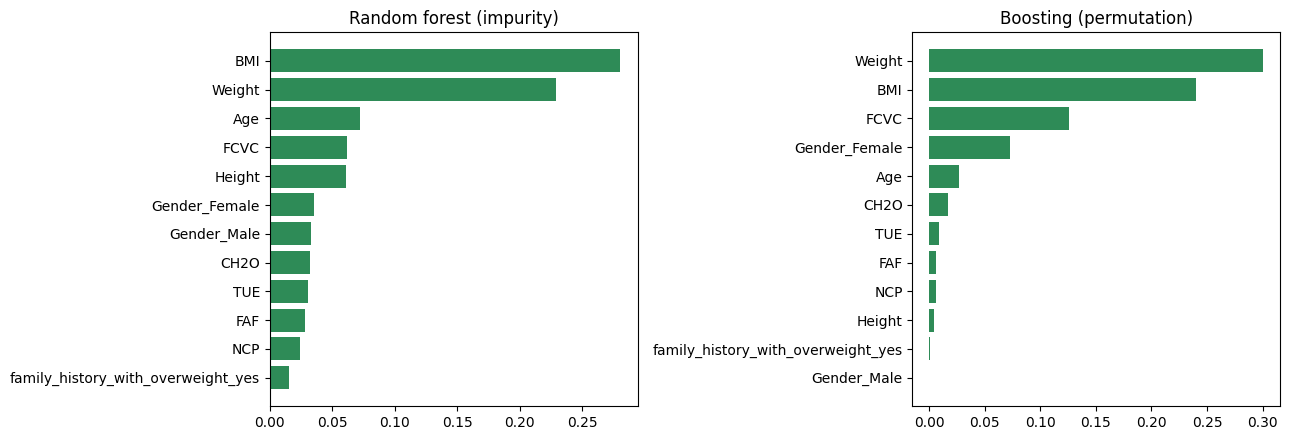

Boosting holdout accuracy: 0.9051
                     precision    recall  f1-score   support

Insufficient_Weight      0.932     0.945     0.938       505
      Normal_Weight      0.879     0.885     0.882       617
 Overweight_Level_I      0.808     0.765     0.786       485
Overweight_Level_II      0.809     0.815     0.812       504
     Obesity_Type_I      0.873     0.885     0.879       582
    Obesity_Type_II      0.971     0.972     0.972       650
   Obesity_Type_III      0.994     0.996     0.995       809

           accuracy                          0.905      4152
          macro avg      0.895     0.895     0.895      4152
       weighted avg      0.905     0.905     0.905      4152



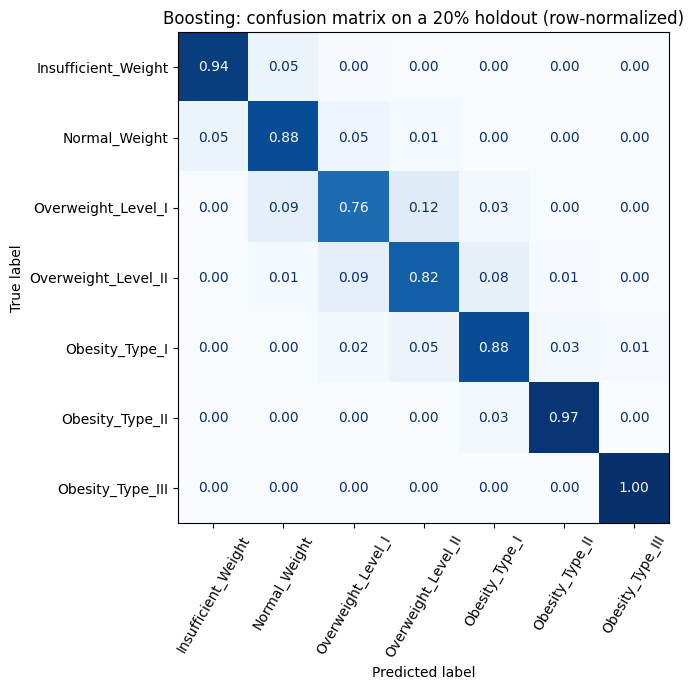

In [11]:
# A depth-3 tree, fitted only for readability, shows the first splits the full tree relies on.
small = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xe, y)
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(small, feature_names=feat_names, class_names=list(small.classes_), filled=True, rounded=True,
          impurity=False, proportion=True, fontsize=8, ax=ax)
ax.set_title('Top three levels of a decision tree (depth limited for readability)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/tree_depth3.png', dpi=150); plt.show()

# Importance: impurity-based for the random forest, permutation-based for boosting (on a 20% holdout)
X_tr, X_ho, y_tr, y_ho = train_test_split(Xe, y, test_size=0.2, stratify=y, random_state=42)
gb_ho = HistGradientBoostingClassifier(**{**fitted['Boosting'].get_params()}).fit(X_tr, y_tr)
perm = permutation_importance(gb_ho, X_ho, y_ho, n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.DataFrame({'Random forest (impurity)': fitted['Random forest'].feature_importances_,
                    'Boosting (permutation)': perm.importances_mean}, index=feat_names)
top = imp.sort_values('Random forest (impurity)', ascending=False).head(12)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col in zip(axes, top.columns):
    s = top[col].sort_values(); a.barh(s.index, s.values, color='seagreen'); a.set_title(col)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/importance.png', dpi=150); plt.show()

pred_ho = gb_ho.predict(X_ho)
print(f'Boosting holdout accuracy: {accuracy_score(y_ho, pred_ho):.4f}')
print(classification_report(y_ho, pred_ho, labels=ORDER, digits=3))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_ho, pred_ho, labels=ORDER, xticks_rotation=60, normalize='true',
                                        values_format='.2f', cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Boosting: confusion matrix on a 20% holdout (row-normalized)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/confusion_boosting.png', dpi=150); plt.show()

In [12]:
s = summary
best_name = s.index[0]
tr = s.loc['Decision tree']; bg = s.loc['Bagging']; rfm = s.loc['Random forest']; bo = s.loc['Boosting']
lg = s.loc['Regularized logistic (baseline)']
print(f"Best model by 5-fold CV: {best_name} ({s.loc[best_name, 'CV accuracy']:.4f}).")
print(f"Single tree {tr['CV accuracy']:.4f} -> bagging {bg['CV accuracy']:.4f} -> random forest {rfm['CV accuracy']:.4f} -> boosting {bo['CV accuracy']:.4f}.")
print(f"Regularized logistic baseline: {lg['CV accuracy']:.4f}.")
print(f"Overfit gaps (train - CV): tree {tr['Overfit gap (train - CV)']:.3f}, bagging {bg['Overfit gap (train - CV)']:.3f}, "
      f"random forest {rfm['Overfit gap (train - CV)']:.3f}, boosting {bo['Overfit gap (train - CV)']:.3f}.")
top3 = imp['Random forest (impurity)'].sort_values(ascending=False).head(3).index.tolist()
print('Top three random forest predictors:', top3)

Best model by 5-fold CV: Boosting (0.9048).
Single tree 0.8763 -> bagging 0.8912 -> random forest 0.9017 -> boosting 0.9048.
Regularized logistic baseline: 0.8669.
Overfit gaps (train - CV): tree 0.024, bagging 0.109, random forest 0.098, boosting 0.057.
Top three random forest predictors: ['BMI', 'Weight', 'Age']


**What the results show** (the printed numbers above are the authoritative values; this text describes the expected pattern and should be checked against them):

* **A single tree is the weakest tree model.** CV picks a moderate depth because a deep tree memorizes the training rows (training accuracy near 1.0 with a large gap to CV). Its strength is readability: the depth-3 tree shows that the first splits are almost all on **BMI** (or Weight and Height), with cut-points close to the clinical BMI thresholds of 18.5, 25, 30, 35 and 40, so the model largely rediscovers how the labels were defined.
* **Bagging reduces that variance.** Averaging 300 bootstrapped trees raises accuracy over the single tree, and the out-of-bag estimate closely matches 5-fold CV, which confirms that OOB error is a reliable test-error estimate.
* **Random forests usually add a little more** by sampling a subset of predictors at each split. That decorrelates the trees, so the average cancels more error. The gain is small here because one predictor (BMI) is far stronger than the rest, so most trees split on it first regardless.
* **Boosting is typically best.** It grows small trees sequentially, each one correcting the errors of the current ensemble, with the learning rate and early stopping controlling overfitting. It handles the boundary between neighboring classes better than averaging methods.
* **Confusion is between adjacent classes.** The confusion matrix shows most errors between neighbors such as Overweight Level I and II, or Normal Weight and Overweight Level I, where BMI values overlap near the cut-points. Obesity Type III is classified almost perfectly. In this synthetic data, Gender also helps separate Obesity Types II and III.
* **Importance must be read with correlation in mind.** Height, Weight and BMI are strongly correlated, so impurity importance is shared among them; permutation importance on the holdout is more trustworthy and still ranks BMI and Weight first, followed by Age and Gender. Lifestyle variables (vegetable intake, physical activity, water intake) contribute, but much less.
* **Assumptions.** The Kolmogorov–Smirnov distances between train and test are tiny, so CV accuracy should carry over to the Kaggle leaderboard. The regularized logistic baseline trails the tree ensembles, which shows the value of modeling the nonlinear, threshold-shaped relationship between BMI and the classes.